Initial Data Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         10 non-null     int64  
 1   Gender      10 non-null     object 
 2   Salary      9 non-null      float64
 3   Department  10 non-null     object 
 4   Experience  10 non-null     int64  
 5   Purchased   10 non-null     object 
dtypes: float64(1), int64(2), object(3)
memory usage: 612.0+ bytes
None

Missing Values in Each Column:
 Age           0
Gender        0
Salary        1
Department    0
Experience    0
Purchased     0
dtype: int64


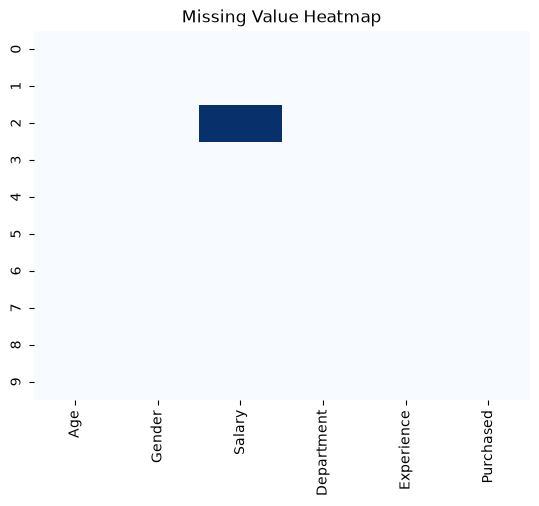

KeyError: 'Married'

In [2]:
# Importing required libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load the dataset
df = pd.read_csv('/content/test_Y3wMUE5_7gLdaTN.csv')

# Clean column names by stripping trailing/leading whitespaces
df.columns = df.columns.str.strip()

# Display basic information
print('Initial Data Overview:')
print(df.info())

# 1. Handling Missing Values
print('\nMissing Values in Each Column:\n', df.isnull().sum())
sns.heatmap(df.isnull(), cbar=False, cmap='Blues')
plt.title('Missing Value Heatmap')
plt.show()

# Fill missing values for categorical features safely
cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in cat_cols:
  if col in df.columns and not df[col].dropna().empty:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing values for numerical features safely
if 'LoanAmount' in df.columns:
  df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

if 'Loan_Amount_Term' in df.columns:
  df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(
      df['Loan_Amount_Term'].mode()[0]
  )

if 'Credit_History' in df.columns:
  df['Credit_History'] = df['Credit_History'].fillna(
      df['Credit_History'].mode()[0]
  )

# 2. Removing Duplicates
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
print(f'\nRemoved {initial_rows - df.shape[0]} duplicate rows.')

# 3. Data Type Conversion
if 'Dependents' in df.columns:
  df['Dependents'] = (
      df['Dependents'].astype(str).replace('3+', '3').fillna('0')
  )
  df['Dependents'] = pd.to_numeric(df['Dependents'], errors='coerce').fillna(0)
  df['Dependents'] = df['Dependents'].astype(int)

# 4. Ensuring Categorical Consistency
for col in ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']:
  if col in df.columns:
    df[col] = df[col].astype(str).str.strip().str.capitalize()

# 5. Normalization & Standardization
min_max_scaler = MinMaxScaler()
scale_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
existing_scale_cols = [c for c in scale_cols if c in df.columns]

if existing_scale_cols:
  df[existing_scale_cols] = min_max_scaler.fit_transform(
      df[existing_scale_cols]
  )

if 'Credit_History' in df.columns:
  scaler = StandardScaler()
  df[['Credit_History']] = scaler.fit_transform(df[['Credit_History']])

# 6. Final Overview
print('\nCleaned Data Summary:')
print(df.info())
print(df.head())